<a href="https://colab.research.google.com/github/fforster/alerce-iucaa-2026/blob/main/00_introduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 00 · Introduction: ALeRCE, ZTF and LSST

**ALeRCE multisurvey tutorial — IUCAA 2026** · ~15 min

In this tutorial you will learn how to use the **ALeRCE broker** to do science with alerts from two surveys at once:

* **ZTF** (Zwicky Transient Facility, Palomar, 2018–): $g, r, i$, ~2 day cadence, northern sky, limiting mag ~20.5.
* **LSST** (Vera C. Rubin Observatory, Chile, 2025–): $u, g, r, i, z, y$, limiting mag ~24.5, millions of alerts per night.

ALeRCE ("Automatic Learning for the Rapid Classification of Events") ingests these alert streams in real time,
cross-matches them with other catalogs, computes light-curve **features**, **classifies** every object with
machine-learning models and puts everything in a single **multisurvey database** that you can query.

### Roadmap (≈ 3 h)

| Notebook | Topic | Time |
|---|---|---|
| **00** | Introduction and access tools (this notebook) | 15 min |
| **01** | The multisurvey database: every table, look-up tables, helper functions | 45 min |
| **02** | One source, two surveys: three objects seen by ZTF *and* LSST | 25 min |
| **03** | Supernovae: DELIGHT host galaxies and spectroscopic redshifts | 35 min |
| **04** | AGN: multiwavelength crossmatches and redshifts | 30 min |
| **05** | Variable stars: periods from combined ZTF + LSST light curves | 30 min |

Notebooks go from simple to complex: each one starts with a single object and ends with a sample.

## 1. How do I get ALeRCE data?

| Tool | URL | Good for |
|---|---|---|
| **ZTF Explorer** | https://alerce.online | browsing ZTF objects |
| **LSST Explorer** | https://lsst.alerce.online | browsing LSST objects |
| **Experimental explorer** (ALeRCE Labs) | https://explorer-experiment.alerce.online | ZTF + LSST *together*, crossmatches, spectroscopic redshifts, ZTF data releases |
| **Multisurvey REST API** | https://api-lsst.alerce.online | one object at a time, JSON, fast |
| **TAP service** (ADQL, a dialect of SQL) | https://tap.alerce.online/tap | arbitrary queries over the full database, samples |
| **catsHTM crossmatch** | https://catshtm.alerce.online | nearest source in ~15 external catalogs (2MASS, WISE, GALEX, XMM, SDSS, …) |
| Python client | `pip install alerce` | wrapper around the API |

Rule of thumb: **API for one object, TAP for many objects, explorer to look at them.**

More: https://science.alerce.online/alerce-labs/ and https://alerce.science

## 2. Setup

Run the next cell once. On Google Colab it installs the packages we need and downloads the small helper
library `alerce_ms.py` that we will build in notebook 01. Locally, install `requirements.txt` first.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip -q install pyvo astroquery
    !wget -q -N https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/alerce_ms.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import pyvo

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 3. Hello, TAP

The TAP service speaks **ADQL**. `pyvo` sends a query and returns an astropy table, which we convert to pandas.
Let us ask which surveys are in the database:

In [2]:
tap = pyvo.dal.TAPService("https://tap.alerce.online/tap")

surveys = tap.search("SELECT * FROM alerce_tap.sid_lut").to_table().to_pandas()
surveys

,sid,tid,survey_name,created_date
0,0,0,ZTF,2026-04-29
1,1,1,LSST DIA Object,2026-04-29
2,2,1,LSST SS Object,2026-04-29


Three "surveys": ZTF (`sid = 0`), LSST difference-image objects (`sid = 1`, *diaObjects*) and LSST solar-system
objects (`sid = 2`). `tid` is the telescope (0 = Palomar/ZTF camera, 1 = Rubin).

All tables live in the schema `alerce_tap`. How many tables are there?

In [3]:
tables = tap.search("SELECT table_name FROM TAP_SCHEMA.tables WHERE schema_name = 'alerce_tap'").to_table().to_pandas()
print(len(tables), "tables")
tables.table_name.str.replace("alerce_tap.", "").values

31 tables


<ArrowStringArray>
[                'object',             'ztf_object',        'lsst_dia_object',         'lsst_ss_object',        'lsst_mpc_orbits',              'detection',          'ztf_detection',
         'lsst_detection',      'lsst_ss_detection',      'forced_photometry',  'ztf_forced_photometry', 'lsst_forced_photometry',      'ztf_non_detection',                 'ztf_ss',
                'ztf_ps1',               'ztf_gaia',        'ztf_dataquality',          'ztf_reference',                'magstat',             'classifier',               'taxonomy',
            'probability',                'feature',       'feature_name_lut',    'feature_version_lut',                'sid_lut',                   'band',                 'xmatch',
         'catalog_id_lut',                'allwise',         'gaiadr3_source']
Length: 31, dtype: str

We will visit **all 31 tables** in notebook 01.

## 4. Hello, API

The multisurvey REST API is split in small services: `object_api`, `lightcurve_api`, `probability_api`,
`magstat_api`, `crossmatch_api`, `stamps_api`, `classifier_api`. Each answers plain HTTP GET requests with JSON.
Every request says which survey it refers to (`survey_id=ztf` or `survey_id=lsst`).

In [4]:
API = "https://api-lsst.alerce.online"

r = requests.get(f"{API}/object_api/object", params={"oid": "ZTF26aaonmha", "survey_id": "ztf"}, timeout=60)
r.json()

{'oid': 36029005852662990,
 'tid': 0,
 'sid': 0,
 'meanra': 149.92867128193834,
 'meandec': 0.41844832171922647,
 'sigmara': 0.002946957545275382,
 'sigmadec': 0.002946878784333006,
 'firstmjd': 61121.31626159977,
 'lastmjd': 61185.21143520018,
 'deltamjd': 63.89517360040918,
 'n_det': 39,
 'n_forced': 36,
 'n_non_det': 54,
 'created_date': '2026-07-09T00:00:00',
 'updated_date': '2026-07-10T00:00:00'}

Note that ZTF names like `ZTF26aaonmha` become an **integer** `oid` inside the database (here
`36029005852662990`). We will see why in notebook 01.

Which classifiers exist?

In [5]:
classifiers = requests.get(f"{API}/classifier_api/classifiers", timeout=60).json()
pd.DataFrame(classifiers)[["classifier_id", "classifier_name", "classifier_version", "survey_id", "classes"]]

,classifier_id,classifier_name,classifier_version,survey_id,classes
0,5,lc_classifier_BHRF_forced_phot,2.2.0,0,"[SNIa, SESN, SNII, SNIIn, SLSN, TDE, Microlens..."
1,9,lc_classifier_BHRF_forced_phot_periodic,2.2.0,0,"[LPV, EA, EB/EW, Periodic-Other, RSCVn, CEP, R..."
2,8,lc_classifier_BHRF_forced_phot_stochastic,2.2.0,0,"[Microlensing, QSO, AGN, Blazar, YSO, CV/Nova]"
3,6,lc_classifier_BHRF_forced_phot_top,2.2.0,0,"[Transient, Stochastic, Periodic]"
4,7,lc_classifier_BHRF_forced_phot_transient,2.2.0,0,"[SNIa, SESN, SNII, SNIIn, SLSN, TDE]"
5,4,stamp_classifier,1.0.4,0,"[SN, AGN, VS, asteroid, bogus, satellite]"
6,2,stamp_classifier_2025_beta,2.1.1,0,"[SN, AGN, VS, asteroid, bogus, satellite]"
7,1,stamp_classifier_rubin_beta,2.0.1,1,"[SN, AGN, VS, asteroid, bogus]"
8,3,stamp_classifier_rubin_beta_20260421,2.0.2,1,"[SN, AGN, VS, asteroid, bogus]"


* **Stamp classifiers** use the image cut-outs of the *first* alert: fast, coarse classes (SN, AGN, VS, asteroid, bogus).
  There is one for ZTF and two (beta) versions for Rubin.
* **Light-curve classifiers** (ZTF, `lc_classifier_BHRF_forced_phot*`) use the full light curve, including forced
  photometry: a hierarchical random forest with a *top* level (Transient / Stochastic / Periodic) and one model per branch.

## 5. Hello, explorer

Today we will use three objects in the COSMOS field that were detected by **both** ZTF and LSST
(from the ALeRCE Labs slide). Click on them: the experimental explorer shows both surveys together.

In [6]:
from IPython.display import HTML, display

examples = {
    "ZTF17aabhbva": "RR Lyrae star (periodic variable)",
    "ZTF26aaonmha": "SN 2026gzf, a type Ic-BL supernova",
    "ZTF20acyxpwi": "quasar (AGN)",
}
for name, what in examples.items():
    url = f"https://explorer-experiment.alerce.online/?survey=ztf&oid={name}"
    display(HTML(f'<b>{name}</b> — {what}: <a href="{url}" target="_blank">{url}</a>'))

## 6. A first plot

Let us put everything together: the LSST light curve of the supernova from the API. The LSST counterpart of
`ZTF26aaonmha` is the diaObject `314003014107006318` (in notebook 02 you will find it yourself).
LSST photometry is given as **flux in nano-Jansky** (nJy); `psfFlux` is measured on the *difference* image.

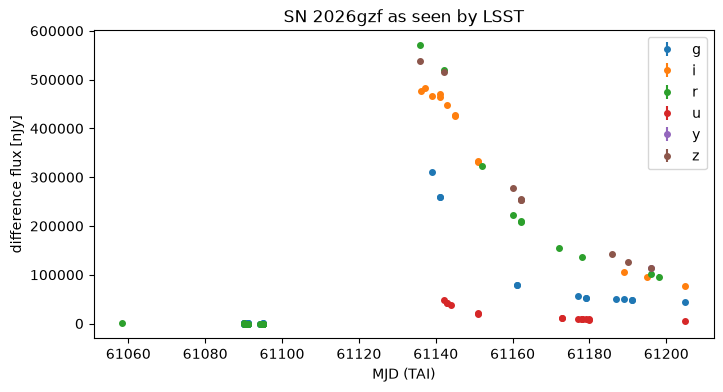

In [7]:
lc = requests.get(f"{API}/lightcurve_api/lightcurve",
                  params={"oid": 314003014107006318, "survey_id": "lsst"}, timeout=60).json()
det = pd.DataFrame(lc["detections"])
band_map = det.band_map.iloc[0]          # {"1": "g", "2": "r", ...}
det["band_name"] = det.band.astype(str).map(band_map)

fig, ax = plt.subplots(figsize=(8, 4))
for band, g in det.groupby("band_name"):
    ax.errorbar(g.mjd, g.psfFlux, g.psfFluxErr, fmt="o", ms=4, label=band)
ax.set_xlabel("MJD (TAI)")
ax.set_ylabel("difference flux [nJy]")
ax.set_title("SN 2026gzf as seen by LSST")
ax.legend();

AB magnitudes follow from $m = 31.4 - 2.5\log_{10}(F/\mathrm{nJy})$: the peak at ~500 000 nJy is $m \approx 17.2$.

### ✏️ Exercise 0.1
Change the code above to plot the LSST light curve of the quasar counterpart `313985345706262538`.
Is it a transient or a variable source? (Hint: look at both `psfFlux` and `scienceFlux`.)

In [8]:
# your code here

**Next:** [01 · The multisurvey database](01_multisurvey_database.ipynb)